# 01 - Market Data & Solar Capture Analysis

# Objective

This notebook analyses the historical market value of German solar generation using hourly DE-LU day-ahead prices and photovoltaic generation from 2021 to 2025.
 
The analysis focuses on:
 
- Day-ahead price dynamics
- Negative-price exposure
- Solar capture price and capture rate
- Intraday and seasonal production patterns
- Price-volume correlation
 
The objective is to quantify historical solar capture risk before building the PPA valuation model in Notebook 2.



In [941]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


## 1. Data Preparation
This analysis uses publicly available German electricity-market data from SMARD, the market-data platform of the German Federal Network Agency (Bundesnetzagentur).

The initial dataset combines:

- DE-LU hourly day-ahead electricity prices
- German hourly photovoltaic generation

The historical analysis covers 2021-2025. Data are used under the SMARD CC BY 4.0 licence.


In [942]:
#Get the data directory

DATA_DIR = Path("../data/raw")

price_files = sorted((DATA_DIR / "prices").glob("*.csv"))
solar_files = sorted((DATA_DIR / "solar").glob("*.csv"))

Relevant Columns and Data Types

For the historical analysis, only two market variables are required:

- **DE-LU day-ahead electricity price** in EUR/MWh
- **German photovoltaic generation** in MWh


In [943]:
#defining the column names for price and solar data
PRICE_COL = "Germany/Luxembourg [€/MWh] Calculated resolutions"
SOLAR_COL = "Photovoltaics [MWh] Calculated resolutions"

#function to load price data from csv file and return a cleaned dataframe
def load_price_file(file_path):
    df = pd.read_csv(file_path, sep=";")

    df = df[
        ["Start date", "End date", PRICE_COL]
    ].copy()

    df = df.rename(columns={
        "Start date": "start_date",
        "End date": "end_date",
        PRICE_COL: "price_eur_mwh"
    })

    return df

#function to load solar data from csv file and return a cleaned dataframe, with the solar generation column cleaned and converted to float

def load_solar_file(file_path):
    df = pd.read_csv(file_path, sep=";")

    df = df[
        ["Start date", "End date", SOLAR_COL]
    ].copy()

    df = df.rename(columns={
        "Start date": "start_date",
        "End date": "end_date",
        SOLAR_COL: "solar_generation_mwh"
    })

    df["solar_generation_mwh"] = (
        df["solar_generation_mwh"]
        .str.replace(",", "", regex=False)
        .replace("-", np.nan)
        .astype(float)
    )

    return df

In [944]:
prices = pd.concat(
    [load_price_file(file) for file in price_files],
    ignore_index=True
)

solar = pd.concat(
    [load_solar_file(file) for file in solar_files],
    ignore_index=True
)

# print("Prices shape:", prices.shape)
# print("Solar shape:", solar.shape)

# display(prices.head())
# display(solar.head())

In [945]:
#to get the time format of the start and end date columns, we can check the first row of the dataframes
DATE_FORMAT = "%b %d, %Y %I:%M %p"

for df in [prices, solar]:
    df["start_date"] = pd.to_datetime(
        df["start_date"],
        format=DATE_FORMAT
    )
    df["end_date"] = pd.to_datetime(
        df["end_date"],
        format=DATE_FORMAT
    )



# display(prices.head())
# display(solar.head())

In [946]:
##check date duplicates in the price data


price_duplicates = prices[
    prices["start_date"].duplicated(keep=False)
]

# display(price_duplicates)
#handle duplicates in the price and solar data by adding an occurrence column to each dataframe, which counts the number of occurrences of each start_date and end_date combination

# it is for the annual transmission from winter to summer, where the same start and end date can have multiple prices and solar generation values. The occurrence column will be used to merge the two dataframes on start_date, end_date and occurrence columns.
prices["occurrence"] = (
    prices.groupby(["start_date", "end_date"]).cumcount()
)

solar["occurrence"] = (
    solar.groupby(["start_date", "end_date"]).cumcount()
)


# display(
#     prices[prices["start_date"].duplicated(keep=False)]   #to keep both duplicates, use keep=False
# )


In [947]:
#merge the two dataframes on start_date, end_date and occurrence columns

market = prices.merge(
    solar,
    on=["start_date", "end_date", "occurrence"],
    how="inner",
    validate="one_to_one"
)

validation = pd.Series({
    "Hourly observations": len(market),
    "Missing values": market.isna().sum().sum(),
    "Duplicate merge keys": market.duplicated(
        ["start_date", "end_date", "occurrence"]
    ).sum(),
    "Negative-price hours": (
        market["price_eur_mwh"] < 0
    ).sum(),
    "Negative solar observations": (
        market["solar_generation_mwh"] < 0
    ).sum()
})

display(validation)

Hourly observations            43824
Missing values                     0
Duplicate merge keys               0
Negative-price hours            1539
Negative solar observations        0
dtype: int64

## 2. Historical Market Overview
Before calculating solar capture metrics, we analyse the historical behaviour of German day-ahead electricity prices and photovoltaic generation.

The analysis focuses on:

- Annual electricity-price dynamics
- Negative-price frequency and severity
- Solar-generation seasonality
- Intraday solar production profiles
- Relationship between solar generation and electricity prices

These patterns provide the economic context required to interpret solar capture prices and capture rates.


### Annual Day-Ahead Prices


,average_price_eur_mwh,min_price_eur_mwh,max_price_eur_mwh,negative_price_hours,solar_generation_twh
year,,,,,
2021,96.85,-69.00,620.00,139,46.23
2022,235.45,-19.04,871.00,69,55.73
2023,95.18,-500.00,524.27,301,55.54
2024,78.51,-135.45,936.28,457,63.15
2025,89.32,-250.32,583.40,573,73.78


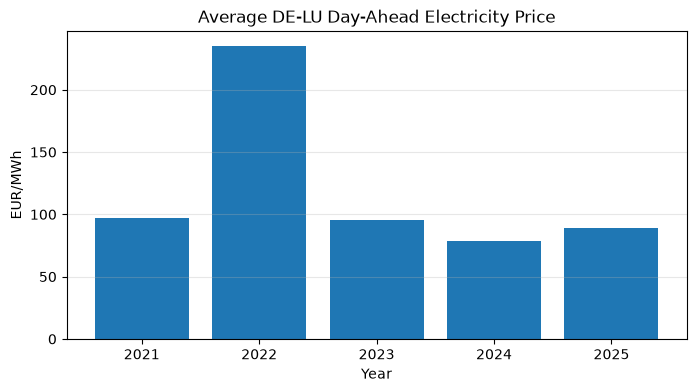

In [948]:
market["year"] = market["start_date"].dt.year

annual_summary = (
    market.groupby("year")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        min_price_eur_mwh=("price_eur_mwh", "min"),
        max_price_eur_mwh=("price_eur_mwh", "max"),
        negative_price_hours=("price_eur_mwh", lambda x: (x < 0).sum()),
        solar_generation_twh=("solar_generation_mwh", lambda x: x.sum() / 1e6),
    )
)

display(annual_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    annual_summary.index,
    annual_summary["average_price_eur_mwh"]
)

ax.set_title("Average DE-LU Day-Ahead Electricity Price")
ax.set_xlabel("Year")
ax.set_ylabel("EUR/MWh")
ax.grid(axis="y", alpha=0.3)

plt.show()

DE-LU day-ahead prices increased sharply during the 2022 European energy crisis before declining and partially normalising from 2023 onward.

### Negative-Price Frequency

Negative-price hours are particularly relevant for solar PPAs because photovoltaic generation is concentrated during daylight hours and can contribute to periods of oversupply.

An increasing frequency of negative prices can therefore reduce solar capture prices even when annual baseload prices remain relatively high.

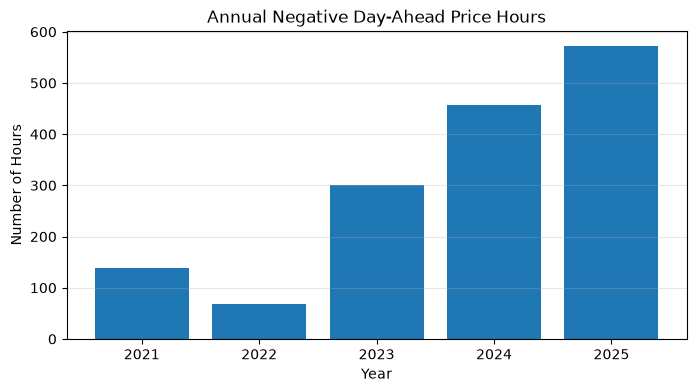

In [949]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    annual_summary.index,
    annual_summary["negative_price_hours"]
)

ax.set_title("Annual Negative Day-Ahead Price Hours")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Hours")
ax.grid(axis="y", alpha=0.3)

plt.show()


Negative-price frequency increased materially over the analysis period. The economic impact on solar assets depends not only on the number of negative-price hours, but also on the share of photovoltaic generation produced during those periods.

### Intraday Solar Generation and Electricity Prices

To assess the relationship between solar production and electricity prices, hourly observations are grouped by hour of day.

Average photovoltaic generation and average DE-LU day-ahead prices are compared across the 24-hour daily cycle.

This provides a first indication of whether solar production is concentrated during hours associated with systematically lower electricity prices.

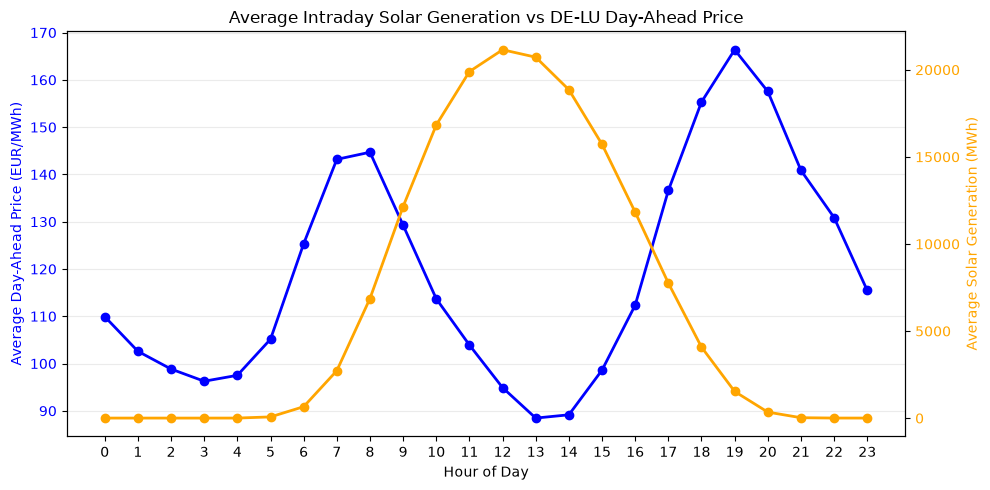

In [950]:
market["hour"] = market["start_date"].dt.hour

hourly_profile = (
    market.groupby("hour")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        average_solar_generation_mwh=("solar_generation_mwh", "mean")
    )
)

fig, ax_price = plt.subplots(figsize=(10, 5))

# Day-ahead price
ax_price.plot(
    hourly_profile.index,
    hourly_profile["average_price_eur_mwh"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Day-Ahead Price"
)

ax_price.set_xlabel("Hour of Day")
ax_price.set_ylabel("Average Day-Ahead Price (EUR/MWh)", color="blue")
ax_price.set_xticks(range(24))
ax_price.grid(axis="y", alpha=0.25)
ax_price.tick_params(axis="y", labelcolor="blue")

# Solar generation
ax_solar = ax_price.twinx()

ax_solar.plot(
    hourly_profile.index,
    hourly_profile["average_solar_generation_mwh"],
    color="orange",
    marker="o",
    linewidth=2,
    label="Solar Generation"
)

ax_solar.set_ylabel("Average Solar Generation (MWh)", color="orange")
ax_solar.tick_params(axis="y", labelcolor="orange")

plt.title("Average Intraday Solar Generation vs DE-LU Day-Ahead Price")

fig.tight_layout()
plt.show()


The intraday profile shows that solar generation is concentrated around midday, when average day-ahead prices are comparatively low. Prices increase again during the evening ramp as solar production declines.

This pattern provides an initial indication of solar capture risk, although the relationship is quantified more precisely through capture rates and price-volume correlations below.

## 3. Solar Capture Price & Capture Rate
### Annual Capture Price and Capture Rate

The solar capture price measures the average electricity price received during hours of photovoltaic generation, weighted by the amount of solar electricity produced.

For each year, the solar capture price is defined as:

$$
P_{\text{capture}}
=
\frac{\sum_{t} P_t Q_t}
{\sum_{t} Q_t}
$$

where:

- $P_t$ is the hourly DE-LU day-ahead electricity price in EUR/MWh.
- $Q_t$ is the hourly solar generation in MWh.

The capture rate compares the production-weighted solar price with the average day-ahead market price:

$$
CR
=
\frac{P_{\text{capture}}}
{P_{\text{market}}}
$$

or, expressed as a percentage:

$$
CR_{\%}
=
\frac{P_{\text{capture}}}
{P_{\text{market}}}
\times 100
$$

A capture rate below 100% indicates that solar generation tends to occur during hours with below-average electricity prices.

In [951]:
market["solar_market_value_eur"] = (
    market["price_eur_mwh"]
    * market["solar_generation_mwh"]
)

In [952]:
capture_summary = (
    market.groupby("year")
    .agg(
        average_price_eur_mwh=("price_eur_mwh", "mean"),
        solar_generation_mwh=("solar_generation_mwh", "sum"),
        solar_market_value_eur=("solar_market_value_eur", "sum")
    )
)

capture_summary["capture_price_eur_mwh"] = (
    capture_summary["solar_market_value_eur"]
    / capture_summary["solar_generation_mwh"]
)

capture_summary["capture_rate_pct"] = (
    capture_summary["capture_price_eur_mwh"]
    / capture_summary["average_price_eur_mwh"]
    * 100
)

capture_summary["capture_discount_eur_mwh"] = (
    capture_summary["average_price_eur_mwh"]
    - capture_summary["capture_price_eur_mwh"]
)

display(
    capture_summary[
        [
            "average_price_eur_mwh",
            "capture_price_eur_mwh",
            "capture_rate_pct",
            "capture_discount_eur_mwh"
        ]
    ].round(2)
)

,average_price_eur_mwh,capture_price_eur_mwh,capture_rate_pct,capture_discount_eur_mwh
year,,,,
2021,96.85,75.45,77.90,21.40
2022,235.45,222.25,94.40,13.19
2023,95.18,72.17,75.83,23.00
2024,78.51,46.23,58.88,32.29
2025,89.32,46.07,51.58,43.25


We can see that our hypothesis was right and the capture rate and capture price seems to decline over time, meaning that solar produces when energy prices are low.

Indeed, the historical results show a growing divergence between average market prices and solar capture prices.

This divergence measures the economic impact of the solar generation profile: as photovoltaic output becomes increasingly concentrated during lower-price hours, the market value captured by solar generation can deteriorate relative to the baseload market price.

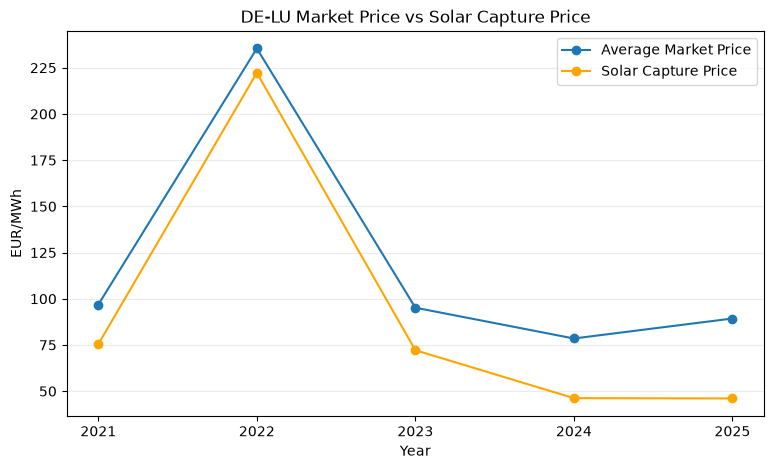

In [953]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    capture_summary.index,
    capture_summary["average_price_eur_mwh"],
    marker="o",
    label="Average Market Price"
)

ax.plot(
    capture_summary.index,
    capture_summary["capture_price_eur_mwh"],
    marker="o",
    color="orange",
    label="Solar Capture Price"
)

ax.set_title("DE-LU Market Price vs Solar Capture Price")
ax.set_xlabel("Year")
ax.set_ylabel("EUR/MWh")
ax.set_xticks(capture_summary.index)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.show()



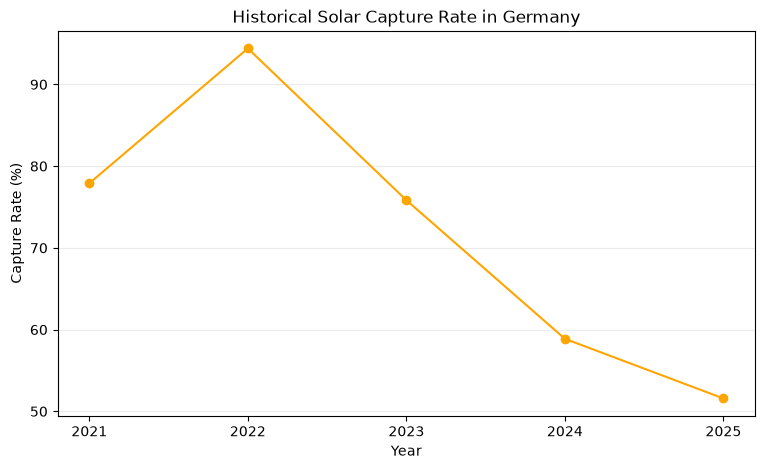

In [954]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    capture_summary.index,
    capture_summary["capture_rate_pct"],
    marker="o",
    color="orange"
)

ax.set_title("Historical Solar Capture Rate in Germany")
ax.set_xlabel("Year")
ax.set_ylabel("Capture Rate (%)")
ax.set_xticks(capture_summary.index)
ax.grid(axis="y", alpha=0.25)

plt.show()

2022 stands out as an exceptional market regime. The average DE-LU day-ahead price reached **€235.45/MWh**, while the solar capture price remained very high at **€222.25/MWh**, resulting in a **94.4% capture rate**.

This does not indicate an absence of solar capture risk. Rather, the unusually high overall level of electricity prices in 2022 meant that solar-producing hours also remained highly valuable in absolute terms. The capture discount was therefore limited to **€13.19/MWh**, despite the solar generation profile.

The following years show a very different pattern. As wholesale prices normalized, the solar capture price increasingly diverged from the average market price. By 2025, the average market price was **€89.32/MWh**, but solar captured only **€46.07/MWh**, reducing the capture rate to **51.6%** and increasing the capture discount to **€43.25/MWh**.

The comparison highlights an important distinction: **capture rate depends not only on the solar production profile, but also on the prevailing market regime and the hourly relationship between generation and prices.**

### Monthly Solar Capture Rate
Annual capture rates can hide significant seasonal differences in the market value of solar generation.

Monthly capture rates are therefore calculated to assess how the value captured by solar generation varies throughout the year.

For each month $m$, the monthly solar capture price is defined as:

$$
P_{\text{capture},m}
=
\frac{\sum_{t \in m} P_t Q_t}
{\sum_{t \in m} Q_t}
$$

where:

- $P_t$ is the hourly DE-LU day-ahead electricity price.
- $Q_t$ is the hourly solar generation.
- $t \in m$ represents all hourly observations within month $m$.

The monthly capture rate is then defined as:

$$
CR_m
=
\frac{P_{\text{capture},m}}
{\overline{P}_m}
$$

or, expressed as a percentage:

$$
CR_{m,\%}
=
\frac{P_{\text{capture},m}}
{\overline{P}_m}
\times 100
$$

where $\overline{P}_m$ is the average day-ahead electricity price during month $m$.

A monthly capture rate below 100% indicates that solar generation is concentrated in hours with below-average electricity prices during that month.

The monthly heatmap highlights the seasonality of this capture discount and how it evolves over time.

In [955]:
market["month"] = market["start_date"].dt.to_period("M")
#M to keep month and year, but not day, hour, minute, second
#dt.month if we only want the month number, but we dont want to keep the year
monthly_capture = (
    market.groupby("month")
    .agg(
        average_price_eur_mwh=(
            "price_eur_mwh",
            "mean"
        ),
        solar_generation_mwh=(
            "solar_generation_mwh",
            "sum"
        ),
        solar_market_value_eur=(
            "solar_market_value_eur",
            "sum"
        )
    )
)


monthly_capture["capture_price_eur_mwh"] = (
    monthly_capture["solar_market_value_eur"]
    / monthly_capture["solar_generation_mwh"]
)

monthly_capture["capture_rate_pct"] = (
    monthly_capture["capture_price_eur_mwh"]
    / monthly_capture["average_price_eur_mwh"]
    * 100
)


In [956]:
#only copy index and capture_rate_pct 
capture_rate_df = monthly_capture[
    ["capture_rate_pct"]
].copy()

#create year index
capture_rate_df["year"] = (
    capture_rate_df.index.year
)
#create month index
capture_rate_df["month_number"] = (
    capture_rate_df.index.month
)


#create matrix for better visualisation of the capture rate by year and month, with years as rows and months as columns

capture_rate_matrix = capture_rate_df.pivot(
    index="year",
    columns="month_number",
    values="capture_rate_pct"
)


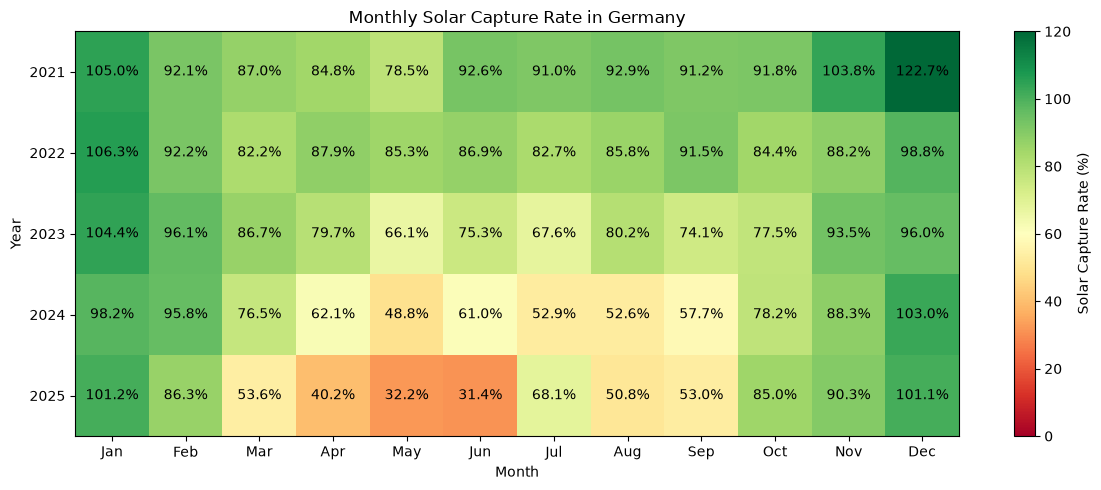

In [957]:
#script for heat matrix of the capture rate by year and month, with years as rows and months as columns

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(12, 5))

heatmap = ax.imshow(
    capture_rate_matrix.values,
    cmap="RdYlGn",
    vmin=0,
    vmax=120,
    aspect="auto"
)

ax.set_xticks(np.arange(12))
ax.set_xticklabels(month_labels)

ax.set_yticks(np.arange(len(capture_rate_matrix.index)))

ax.set_yticklabels(capture_rate_matrix.index)

ax.set_xlabel("Month")
ax.set_ylabel("Year")

ax.set_title(
    "Monthly Solar Capture Rate in Germany"
)


for i in range(capture_rate_matrix.shape[0]):
    for j in range(capture_rate_matrix.shape[1]):

        value = capture_rate_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center"
        )

fig.colorbar(
    heatmap,
    ax=ax,
    label="Solar Capture Rate (%)"
)

fig.tight_layout()
plt.show()

## 4. Negative-Price Exposure
Negative electricity prices are particularly relevant for pay-as-produced solar PPAs because solar generation may remain exposed to the spot market during periods of oversupply.

Two complementary metrics are analysed for each year:

- **Negative-price hours:** number of hours when the DE-LU day-ahead price is below zero.
- **Solar generation exposed to negative prices:** share of annual photovoltaic generation produced during negative-price hours.

The second metric is particularly important because the economic impact of negative prices depends not only on their frequency, but also on whether solar assets are producing during those hours.


In [958]:
market["negative_price"] = market["price_eur_mwh"] < 0

In [959]:
negative_price_summary = (
    market.groupby("year")
    .agg(
        negative_price_hours=(
            "negative_price",
            "sum"
        ),
        total_solar_generation_mwh=(
            "solar_generation_mwh",
            "sum"
        ),
        solar_generation_negative_price_mwh=(
            "solar_generation_mwh",
            lambda x: x[market.loc[x.index, "negative_price"]].sum()
        )
    )
)

negative_price_summary["solar_negative_price_exposure_pct"] = (
    negative_price_summary["solar_generation_negative_price_mwh"]
    / negative_price_summary["total_solar_generation_mwh"]
    * 100
)

#display(negative_price_summary.round(2))


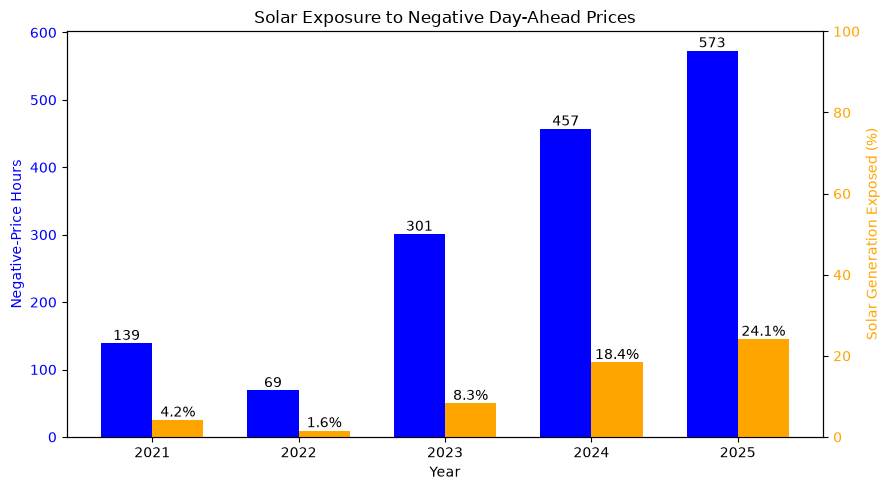

In [960]:
fig, ax_hours = plt.subplots(figsize=(9, 5))

x = np.arange(len(negative_price_summary))
width = 0.35

# Negative-price hours
bars_hours = ax_hours.bar(
    x - width / 2,
    negative_price_summary["negative_price_hours"],
    width,
    color="blue"
)

ax_hours.set_ylabel("Negative-Price Hours", color="blue")
ax_hours.tick_params(axis="y", labelcolor="blue")

# Solar exposure
ax_solar = ax_hours.twinx()

bars_solar = ax_solar.bar(
    x + width / 2,
    negative_price_summary["solar_negative_price_exposure_pct"],
    width,
    color="orange"
)

ax_solar.set_ylabel(
    "Solar Generation Exposed (%)",
    color="orange"
)

ax_solar.tick_params(axis="y", labelcolor="orange")
ax_solar.set_ylim(0, 100)

# Labels
ax_hours.set_xticks(x)
ax_hours.set_xticklabels(negative_price_summary.index)
ax_hours.set_xlabel("Year")
ax_hours.set_title("Solar Exposure to Negative Day-Ahead Prices")

ax_hours.bar_label(bars_hours, fmt="%.0f")
ax_solar.bar_label(bars_solar, fmt="%.1f%%")

fig.tight_layout()
plt.show()

Both negative-price frequency and the share of solar generation exposed to negative prices increased materially over the analysis period. By 2025, 24.1% of annual photovoltaic generation occurred during negative-price hours.

## 5. Price-Volume Correlation
The relationship between photovoltaic generation and electricity prices is quantified using the annual correlation between hourly solar generation and DE-LU day-ahead prices.

A negative correlation indicates that higher solar generation tends to coincide with lower electricity prices, reinforcing the capture-price discount experienced by solar assets.

In [961]:
annual_correlation = (
    market.groupby("year")
    .apply(
        lambda x: x["price_eur_mwh"].corr(
            x["solar_generation_mwh"]
        ),
        include_groups=False
    )
    .rename("price_solar_correlation")
)

#display(annual_correlation.round(3))

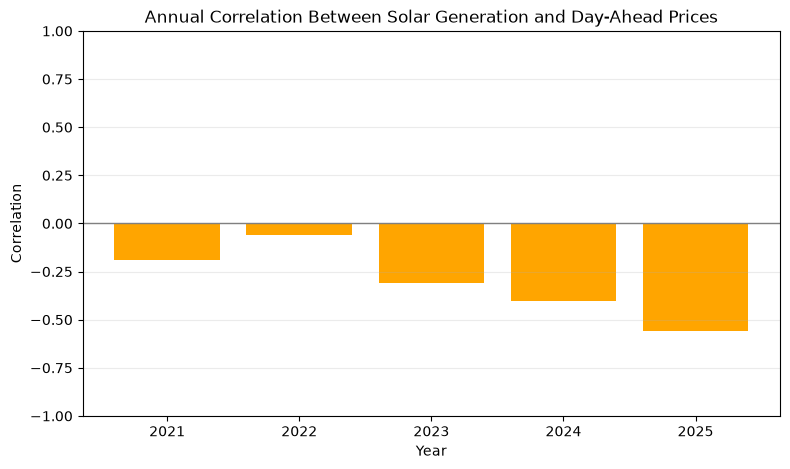

In [962]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    annual_correlation.index,
    annual_correlation.values,
    color="orange"
)

ax.axhline(
    0,
    color="grey",
    linewidth=1
)

ax.set_title("Annual Correlation Between Solar Generation and Day-Ahead Prices")
ax.set_xlabel("Year")
ax.set_ylabel("Correlation")
ax.set_xticks(annual_correlation.index)
ax.set_ylim(-1, 1)
ax.grid(axis="y", alpha=0.25)

plt.show()

In [963]:
market["month"] = market["start_date"].dt.to_period("M")

monthly_correlation = (
    market.groupby("month")
    .apply(
        lambda x: x["price_eur_mwh"].corr(
            x["solar_generation_mwh"]
        ),
        include_groups=False
    )
    .rename("price_solar_correlation")
)

monthly_correlation.index = monthly_correlation.index.to_timestamp()

In [964]:
correlation_df = monthly_correlation.to_frame()

correlation_df["year"] = correlation_df.index.year
correlation_df["month_number"] = correlation_df.index.month

correlation_matrix = correlation_df.pivot(
    index="year",
    columns="month_number",
    values="price_solar_correlation"
)

#display(correlation_matrix.round(2))

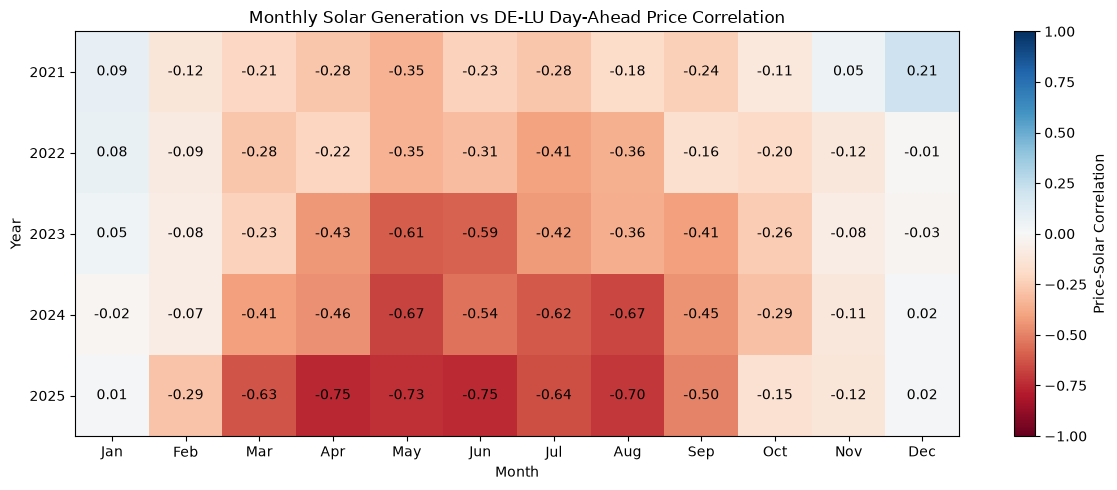

In [965]:
# Labels
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Heatmap
fig, ax = plt.subplots(figsize=(12, 5))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

# Axes
ax.set(
    title="Monthly Solar Generation vs DE-LU Day-Ahead Price Correlation",
    xlabel="Month",
    ylabel="Year",
    xticks=range(12),
    yticks=range(len(correlation_matrix))
)

ax.set_xticklabels(months)
ax.set_yticklabels(correlation_matrix.index)

# Values inside cells
for i in range(correlation_matrix.shape[0]):
    for j in range(correlation_matrix.shape[1]):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

# Color scale
fig.colorbar(
    heatmap,
    ax=ax,
    label="Price-Solar Correlation"
)

fig.tight_layout()
plt.show()

The price-volume relationship becomes increasingly negative over time, particularly during spring and summer.

In 2025, monthly correlations between April and August range from **-0.64 to -0.75**, compared with generally weaker relationships in 2021.

This pattern is consistent with increasing solar cannibalisation pressure: periods of high photovoltaic output increasingly coincide with lower day-ahead prices. For a pay-as-produced solar PPA, this represents material seasonal price-volume risk.

## 6. Key Findings


- The annual solar capture rate declined from **77.9% in 2021 to 51.6% in 2025**, while the capture discount increased from **€21.40/MWh to €43.25/MWh**.
- Capture risk is strongly seasonal. In 2025, monthly capture rates fell to approximately **31–40% between April and June**, compared with around 100% during winter months.
- Negative-price hours increased from **139 to 573**, while the share of solar generation produced during negative-price periods rose from **4.2% to 24.1%**.
- The annual price-volume correlation deteriorated from **-0.19 to -0.56**, with spring and summer 2025 correlations reaching approximately **-0.64 to -0.75**.
- **2022 was an exceptional high-price regime**, with a 94.4% capture rate despite the underlying solar production shape.

Overall, annual baseload prices do not adequately represent the market value of solar generation. A pay-as-produced solar PPA must incorporate hourly production shape, seasonal capture effects, negative-price exposure and price-volume correlation.

In [966]:
#to export the cleaned dataset for use in Notebook 2, we will keep only the cleaned hourly DE-LU price history and export it to a CSV file in the processed-data folder.


# Create the processed-data folder if it does not exist
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Keep only the cleaned hourly DE-LU price history
price_history = market[
    [
        "start_date",
        "price_eur_mwh"
    ]
].copy()

# Export the cleaned dataset for use in Notebook 2
price_history.to_csv(
    PROCESSED_DIR / "de_lu_hourly_prices_2021_2025.csv",
    index=False
)

print(
    f"Exported {len(price_history):,} hourly price observations."
)


Exported 43,824 hourly price observations.
